In [2]:
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

import matplotlib.pyplot as plt

In [3]:
IMG_size = (224, 224)
BATCH_size = 32
epochs = 10

train_dir = "flower_photos/train"
test_dir = "flower_photos/test"
val_dir = "flower_photos/validation"

In [4]:
train_data = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size = IMG_size,
    batch_size = BATCH_size,
    shuffle = True
)

test_data = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size = IMG_size,
    batch_size = BATCH_size,
    shuffle = False
)

val_data = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size = IMG_size,
    batch_size = BATCH_size,
    shuffle = False
)

Found 3540 files belonging to 5 classes.
Found 50 files belonging to 5 classes.
Found 80 files belonging to 5 classes.


In [5]:
class_Name = train_data.class_names

print("Flower Classes")
print(class_Name)
num_class = len(class_Name)


Flower Classes
['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [6]:
Autotune = tf.data.AUTOTUNE

train_data = train_data.prefetch(Autotune)
test_data = test_data.prefetch(Autotune)
val_data = val_data.prefetch(Autotune)

In [7]:
data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.2),
        layers.RandomContrast(0.2)
    ]
)

In [8]:
base_Model = MobileNetV2(
    weights = "imagenet",
    include_top = False,
    input_shape = (224,224,3)
)

base_Model.trainable = False

In [9]:
Model = models.Sequential(
    [
        data_augmentation,
        layers.Rescaling(
            1.0 / 127.5,
            offset = -1
        ),

        base_Model,
        layers.GlobalAveragePooling2D(),

        layers.Dropout(0.3),
        layers.Dense(
            num_class,
            activation="softmax"
        )

    
    ]
)

In [10]:
Model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
Model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [12]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "flower_model.keras",
    monitor="val_accuracy",
    save_best_only=True
)


In [13]:
history = Model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    callbacks=[
        early_stopping,
        checkpoint
    ]
)

Epoch 1/10


C:\Users\muham\AppData\Roaming\Python\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


111/111 ━━━━━━━━━━━━━━━━━━━━ 93s 772ms/step - accuracy: 0.6782 - loss: 0.8644 - val_accuracy: 0.8375 - val_loss: 0.5302
Epoch 2/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 78s 699ms/step - accuracy: 0.8096 - loss: 0.5170 - val_accuracy: 0.8500 - val_loss: 0.4324
Epoch 3/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 88s 793ms/step - accuracy: 0.8367 - loss: 0.4453 - val_accuracy: 0.8625 - val_loss: 0.3904
Epoch 4/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 90s 807ms/step - accuracy: 0.8508 - loss: 0.4081 - val_accuracy: 0.8500 - val_loss: 0.3715
Epoch 5/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 89s 799ms/step - accuracy: 0.8664 - loss: 0.3735 - val_accuracy: 0.8625 - val_loss: 0.3661
Epoch 6/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 98s 878ms/step - accuracy: 0.8621 - loss: 0.3649 - val_accuracy: 0.8875 - val_loss: 0.3561
Epoch 7/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 83s 749ms/step - accuracy: 0.8768 - loss: 0.3421 - val_accuracy: 0.8500 - val_loss: 0.3733
Epoch 8/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 87s 780ms/step - accuracy: 0.8811 - loss: 0.3390 - val

In [14]:
test_loss, test_accuracy = Model.evaluate(test_data)

print("\n==============================")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("==============================")


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 326ms/step - accuracy: 0.8000 - loss: 0.5950

Test Loss: 0.5949792861938477
Test Accuracy: 0.800000011920929


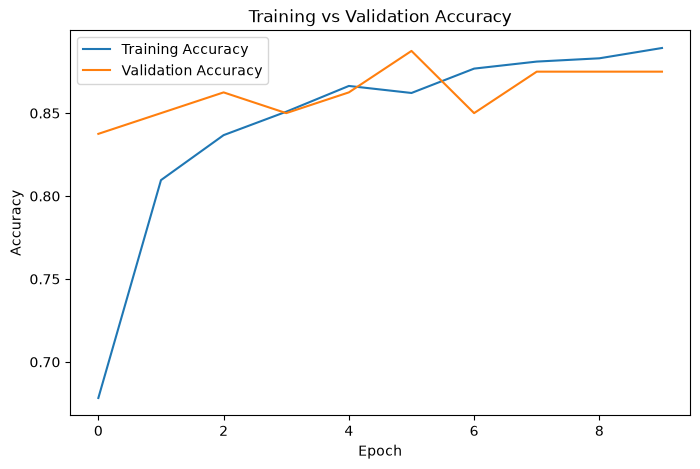

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.show()


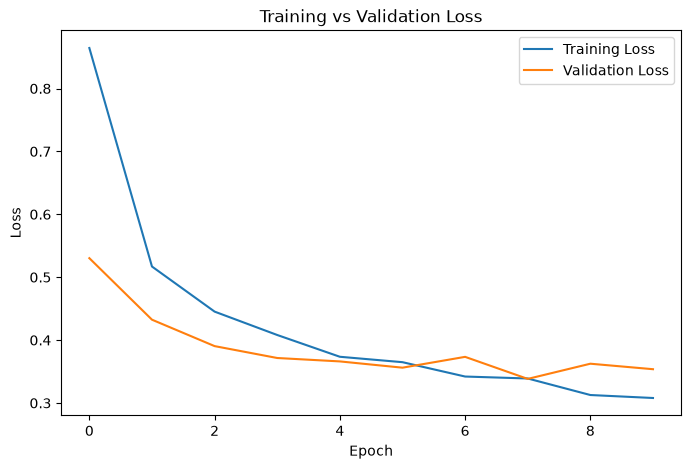

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.show()

In [17]:

def predict_flower(image_path):

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_size
    )

    image_array = tf.keras.utils.img_to_array(image)

    image_array = tf.expand_dims(
        image_array,
        axis=0
    )

    predictions = Model.predict(
        image_array,
        verbose=0
    )

    predicted_index = tf.argmax(
        predictions[0]
    ).numpy()

    predicted_class = class_Name[predicted_index]

    confidence = predictions[0][predicted_index] * 100

    print("\n==============================")
    print("Predicted Flower:", predicted_class)
    print(f"Confidence: {confidence:.2f}%")
    print("==============================")


In [18]:
predict_flower("testing/sun_flower.jpg")


Predicted Flower: sunflowers
Confidence: 99.87%
